# Evaluator: similarity-based visibility selection strength

**Source simulation:** `Visibility_similarity_selection(6).py`. The experiment makes all 100 senders eligible (`visibility_extent = 1.0`) but exposes **exactly 10 sender-solution entries per recipient** every **10 search periods** (effective visibility extent: 0.1). Selection strength determines the composition of these 10 entries. The random component is drawn once per crowd reset and held fixed across recipients and visibility events; the rule-based component is selected by ascending Hamming distance from each recipient's current configuration, excluding the reserved random senders. Sender solutions are refreshed at each event. A common random permutation of recommendation slots determines evaluation order at each event; recipients adopt at most the first perceived improvement.

- `similarity_selection_strength = 0.0`: **10 fixed random senders**, shared by all recipients throughout a crowd reset (limited-visibility benchmark, not search-apart).
- `similarity_selection_strength = 1.0`: **10 most similar sender entries**, selected separately for each recipient at each event.
- Intermediate values `0.2, 0.4, 0.6, 0.8` select **2, 4, 6, 8** entries by similarity, respectively, with fixed random senders completing the pool of 10.

All seven output families concern the **recipient crowd**. Lower breakthrough ranks indicate better discovery. Pairwise diversity measures normalized Hamming distance; adoption quality reflects true NK fitness. Generative potential is estimated by independent local-search continuations of sampled successful adoptions. Overall figures equally average available outcomes across `K=9..17`. Each K-level output already averages 400 landscapes × 5 independent crowd resets (2,000 runs). The simulation saves means, not run-level uncertainty estimates.


In [4]:
from pathlib import Path
import pickle
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

# Matched to the earlier evaluator notebook.
legend_properties = {'weight': 'bold'}
nus_blue = '#003D7C'
nus_orange = '#EF7C00'
morandi_blue = '#046586'
morandi_green = '#28A9A1'
morandi_yellow = '#C9A77C'
morandi_orange = '#F4A016'
morandi_pink = '#F6BBC6'
morandi_red = '#E71F19'
morandi_purple = '#B08BEB'
shallow_grey = '#D3D4D3'

K_colors = [morandi_blue, morandi_orange, morandi_green, morandi_purple,
            morandi_red, morandi_yellow, '#555555', '#B75F91']


def format_axis(ax):
    """Keep the formatting of the provided evaluator."""
    for spine in ax.spines.values():
        spine.set_linewidth(1.5)
        spine.set_color('black')
    ax.grid(alpha=0.5)
    ax.tick_params(axis='both', labelsize=11)
    return ax


def safe_nanmean(values, axis=None):
    """Ignore structurally undefined adoption values, retaining all-NaN as NaN."""
    with warnings.catch_warnings():
        warnings.simplefilter('ignore', category=RuntimeWarning)
        return np.nanmean(values, axis=axis)


In [5]:
# =========================
# Experiment configuration — Visibility_similarity_selection(6).py
# =========================
N = 18
agent_num = 100
knowledge_breadth = 12
landscape_iteration = 400  # Documentation only; averages were computed by the simulation.
solver_reset_num = 5       # Documentation only; included in upstream averages.
search_iteration = 300
K_list = list(range(9, N))
visibility_extent = 1.0
recommendation_num = 10
similarity_selection_strength_list = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]
visibility_interval = 10
generative_horizon = 30  # Documentation only; used upstream.
generative_replications = 30
generative_sample_size = 5
generative_seed = 20261119

# Use the directory containing the six sets of seven simulation pickle files.
# Set to your experiment output directory if pickles are not in the working directory.
# None searches the working directory and the common local subfolders listed below.
result_folder = r"/Volumes/T7/data/gst-1010-26/ISR_Visibility_5/Selection_fixed_num_2/Similarity_based"

# Set to False to review results without saving figures.
save_figures = True
strict_loading = True  # Set False to inspect valid partial results from an unfinished run.

candidate_folders = [Path.cwd(), Path.cwd() / 'Results', Path.cwd() / 'results',
                     Path.cwd() / 'output', Path.cwd() / 'data']
expected_example = (
    f'visibility_similarity_selection_strength_{similarity_selection_strength_list[0]}'
    f'_recommendation_num_{recommendation_num}_interval_{visibility_interval}'
    f'_breakthrough_rank_across_K_size_{agent_num}'
)

if result_folder is None:
    result_folder = next((folder for folder in candidate_folders
                          if (folder / expected_example).is_file()), Path.cwd())
result_folder = Path(result_folder).expanduser()
figure_folder = result_folder / 'visibility_similarity_selection_strength_figures'
if save_figures:
    figure_folder.mkdir(parents=True, exist_ok=True)

# All six settings are shown. No values are omitted from figures.
x = np.asarray(similarity_selection_strength_list, dtype=float)
priority_counts = [int(round(strength * recommendation_num))
                   for strength in similarity_selection_strength_list]
print('Result folder:', result_folder)
print('Output folder:', figure_folder)
print('Example expected file:', expected_example)
print('Folder exists:', result_folder.exists())
print('Similarity-prioritized recommendations per treatment:', dict(zip(similarity_selection_strength_list, priority_counts)))

Result folder: /Volumes/T7/data/gst-1010-26/ISR_Visibility_5/Selection_fixed_num_2/Similarity_based
Output folder: /Volumes/T7/data/gst-1010-26/ISR_Visibility_5/Selection_fixed_num_2/Similarity_based/visibility_similarity_selection_strength_figures
Example expected file: visibility_similarity_selection_strength_0.0_recommendation_num_10_interval_10_breakthrough_rank_across_K_size_100
Folder exists: True
Similarity-prioritized recommendations per treatment: {0.0: 0, 0.2: 2, 0.4: 4, 0.6: 6, 0.8: 8, 1.0: 10}


## 2. Load and validate the seven outcome families

For each treatment and outcome, the simulation writes a pickle with the exact filename pattern:

`visibility_similarity_selection_strength_{strength}_recommendation_num_{number}_interval_{interval}_{DV}_across_K_size_{agent_num}`

Six outcomes have shape `(similarity selection strength, K)`. The cumulative adoption-quality trajectory has shape `(similarity selection strength, K, visibility event)`. The loader checks all six strengths, nine values of `K`, 30 visibility events, and all 42 expected files. In non-strict mode, missing or malformed results remain `NaN` rather than being replaced by zeros.

In [6]:
scalar_dvs = [
    'breakthrough_rank',
    'breakthrough_fitness',
    'pairwise_diversity',
    'unique_solution_count',
    'adopted_solution_fitness',
    'generative_potential',
]
trajectory_dv = 'adopted_solution_fitness_across_time'
expected_events = search_iteration // visibility_interval


def result_file(strength, dv):
    filename = (
        f'visibility_similarity_selection_strength_{strength}'
        f'_recommendation_num_{recommendation_num}_interval_{visibility_interval}'
        f'_{dv}_across_K_size_{agent_num}'
    )
    return result_folder / filename


def load_pickle(path):
    with open(path, 'rb') as infile:
        return pickle.load(infile)


def load_visibility_similarity_results(strict=True):
    n_strength = len(similarity_selection_strength_list)
    n_K = len(K_list)
    data = {dv: np.full((n_strength, n_K), np.nan) for dv in scalar_dvs}
    data[trajectory_dv] = np.full((n_strength, n_K, expected_events), np.nan)
    missing_files = []
    invalid_files = []

    for i, strength in enumerate(similarity_selection_strength_list):
        for dv in scalar_dvs + [trajectory_dv]:
            path = result_file(strength, dv)
            if not path.is_file():
                missing_files.append(path.name)
                continue
            try:
                values = np.asarray(load_pickle(path), dtype=float)
            except (OSError, EOFError, pickle.UnpicklingError, TypeError, ValueError) as exc:
                invalid_files.append((path.name, str(exc)))
                continue
            shape = (n_K, expected_events) if dv == trajectory_dv else (n_K,)
            if values.shape != shape:
                invalid_files.append((path.name, f'got {values.shape}; expected {shape}'))
                continue
            data[dv][i] = values

    n_expected = n_strength * (len(scalar_dvs) + 1)
    print(f'Files loaded: {n_expected - len(missing_files) - len(invalid_files)} / {n_expected}')
    print('Array shapes:', {dv: value.shape for dv, value in data.items()})

    if missing_files:
        print(f'\nMissing files ({len(missing_files)}):')
        for filename in missing_files[:12]:
            print('  ', filename)
        if len(missing_files) > 12:
            print('  ...')
    if invalid_files:
        print(f'\nInvalid files ({len(invalid_files)}):')
        for name, issue in invalid_files[:12]:
            print('  ', name, ':', issue)

    if strict and (missing_files or invalid_files):
        raise FileNotFoundError(
            'Missing/invalid selection-strength results. Check result_folder, agent_num, '
            'recommendation_num, visibility_interval, and similarity_selection_strength_list; '
            'or set strict_loading=False for incomplete runs. First expected file: '
            + str(result_file(similarity_selection_strength_list[0], 'breakthrough_rank'))
        )
    if not any(np.isfinite(data[dv]).any() for dv in scalar_dvs):
        raise FileNotFoundError('No valid scalar pickle outputs found in ' + str(result_folder))
    return data


data = load_visibility_similarity_results(strict=strict_loading)

Files loaded: 42 / 42
Array shapes: {'breakthrough_rank': (6, 9), 'breakthrough_fitness': (6, 9), 'pairwise_diversity': (6, 9), 'unique_solution_count': (6, 9), 'adopted_solution_fitness': (6, 9), 'generative_potential': (6, 9), 'adopted_solution_fitness_across_time': (6, 9, 30)}


In [7]:
# =========================
# Data checks and long-form details
# =========================
checks = {
    'breakthrough_rank': (1, 2 ** N),
    'breakthrough_fitness': (0, 1),
    'pairwise_diversity': (0, 1),
    'unique_solution_count': (1, agent_num),
    'adopted_solution_fitness': (0, 1),
}
for dv, (minimum, maximum) in checks.items():
    finite = data[dv][np.isfinite(data[dv])]
    outside = np.count_nonzero((finite < minimum - 1e-8) | (finite > maximum + 1e-8))
    print(f'{dv:29s} finite={finite.size:3d} / {data[dv].size:3d}; outside expected range={outside}')

# No numeric range is assumed for generative potential without the Crowd implementation.
finite_generative = np.isfinite(data['generative_potential'])
print(f'generative_potential          finite={finite_generative.sum():3d} / {finite_generative.size:3d}')

# The trajectory's final cumulative mean should match the scalar adoption-quality
# measure for each (similarity_selection_strength, K), up to floating-point differences.
last_trajectory = data[trajectory_dv][:, :, -1]
both_defined = np.isfinite(last_trajectory) & np.isfinite(data['adopted_solution_fitness'])
if both_defined.any():
    gap = np.max(np.abs(last_trajectory[both_defined] - data['adopted_solution_fitness'][both_defined]))
    print('Max discrepancy: final trajectory vs. scalar adoption quality =', round(float(gap), 12))

rows = []
for i, strength in enumerate(similarity_selection_strength_list):
    for j, K in enumerate(K_list):
        row = {'similarity_selection_strength': strength, 'K': K}
        for dv in scalar_dvs:
            row[dv] = data[dv][i, j]
        rows.append(row)

detailed_results = pd.DataFrame(rows)
print('\nDetailed data preview (one observation per similarity selection strength × K):')
# display(detailed_results.head(12).round(4))

breakthrough_rank             finite= 54 /  54; outside expected range=0
breakthrough_fitness          finite= 54 /  54; outside expected range=0
pairwise_diversity            finite= 54 /  54; outside expected range=0
unique_solution_count         finite= 54 /  54; outside expected range=0
adopted_solution_fitness      finite= 54 /  54; outside expected range=0
generative_potential          finite= 54 /  54
Max discrepancy: final trajectory vs. scalar adoption quality = 0.0

Detailed data preview (one observation per similarity selection strength × K):


## 3. Main outcomes across similarity selection strength

Each figure displays all six treatments, from **fixed random sender recommendations** (`0.0`) to fully **recipient-specific similarity selection** (`1.0`). The recommendation pool always contains **10 entries**, so the horizontal axis measures **selection strength**, not visibility extent. Overall curves give equal weight to `K=9..17`; the adjacent plots retain each `K` separately. In this experiment, prioritization uses **similarity (smallest Hamming distance)** relative to the recipient's current configuration.

Saved: /Volumes/T7/data/gst-1010-26/ISR_Visibility_5/Selection_fixed_num_2/Similarity_based/visibility_similarity_selection_strength_figures/Breakthrough_across_similarity_selection_strength.png


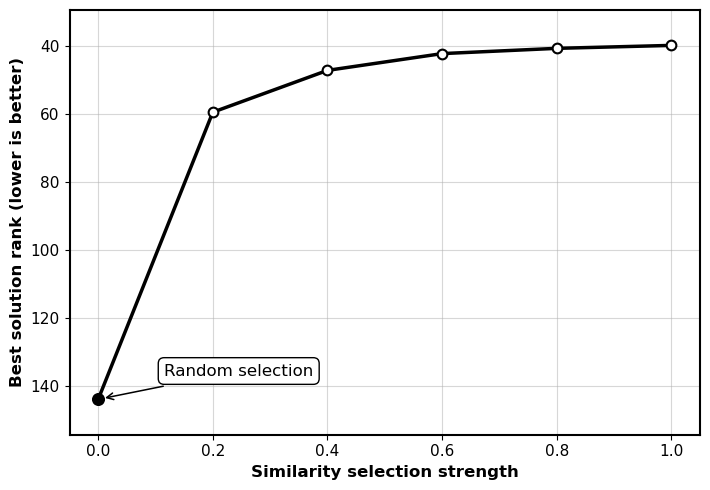

In [8]:
# =========================
# Best solution rank across similarity selection strength (average across K)
# =========================
fig, ax = plt.subplots(figsize=(7.2, 5.0))

# -------------------------
# Axis formatting
# -------------------------
for spine in ax.spines.values():
    spine.set_linewidth(1.5)
    spine.set_color("black")

ax.grid(alpha=0.5)
ax.tick_params(axis="both", labelsize=11)

# -------------------------
# Data
# -------------------------
x = np.asarray(similarity_selection_strength_list)
y_rank = safe_nanmean(data["breakthrough_rank"], axis=1)

# Identify random-selection benchmark point
zero_idx = 0
zero_x, zero_y = x[zero_idx], y_rank[zero_idx]

# -------------------------
# Main curve
# -------------------------
ax.plot(
    x,
    y_rank,
    marker="o",
    linewidth=2.5,
    markersize=7,
    color="k",
    markerfacecolor="white",
    markeredgecolor="black",
    markeredgewidth=1.5,
    zorder=2,
)

# Give endpoint observations some breathing room
ax.margins(x=0.05, y=0.10)

# Highlight random-selection benchmark
ax.scatter(
    zero_x,
    zero_y,
    s=70,
    color="black",
    zorder=3,
)

# -------------------------
# Annotation-box style
# -------------------------
textbox_style = dict(
    boxstyle="round,pad=0.35",
    facecolor="white",
    edgecolor="black",
    linewidth=1.0,
)

arrow_style = dict(
    arrowstyle="->",
    linewidth=1.1,
    color="black",
    shrinkA=5,
    shrinkB=5,
)

# -------------------------
# Random-selection annotation
# -------------------------
ax.annotate(
    "Random selection",
    xy=(zero_x, zero_y),
    xycoords="data",
    xytext=(0.15, 0.15),
    textcoords="axes fraction",
    ha="left",
    va="center",
    fontsize=12,
    bbox=textbox_style,
    arrowprops=arrow_style,
    annotation_clip=True,
    zorder=4,
)

# -------------------------
# Axes
# -------------------------
ax.invert_yaxis()  # Rank 1 is best; invert so a better rank is visually higher.
ax.set_xticks(x)

ax.set_xlabel(
    "Similarity selection strength",
    fontweight="bold",
    fontsize=12,
)

ax.set_ylabel(
    "Best solution rank (lower is better)",
    fontweight="bold",
    fontsize=12,
)

plt.tight_layout()

if save_figures:
    output_png = figure_folder / "Breakthrough_across_similarity_selection_strength.png"

    plt.savefig(
        output_png,
        dpi=300,
        bbox_inches="tight",
        transparent=True,
    )

    print("Saved:", output_png)

plt.show()

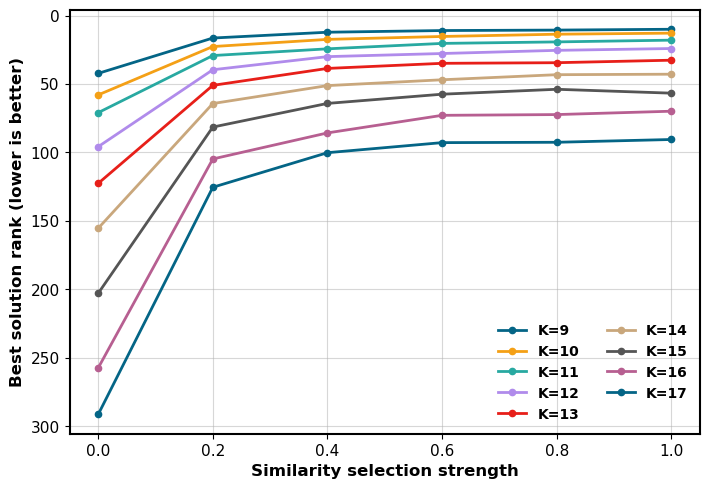

In [9]:
# Best solution rank across similarity selection strength (by K).
fig, ax = plt.subplots(figsize=(7.2, 5.0))
format_axis(ax)
for j, K in enumerate(K_list):
    ax.plot(x, data['breakthrough_rank'][:, j],
            marker='o', linewidth=2.0, markersize=4.5,
            label=f'K={K}', color=K_colors[j % len(K_colors)])
ax.invert_yaxis()
ax.set_xticks(x)
ax.set_xlabel('Similarity selection strength', fontweight='bold', fontsize=12)
ax.set_ylabel('Best solution rank (lower is better)', fontweight='bold', fontsize=12)
ax.legend(frameon=False, ncol=2, prop={'weight': 'bold', 'size': 10})
fig.tight_layout()
if save_figures:
    fig.savefig(figure_folder / 'Breakthrough_by_K_across_similarity_selection_strength.png', dpi=300, bbox_inches='tight', transparent=True)
plt.show()

Saved: /Volumes/T7/data/gst-1010-26/ISR_Visibility_5/Selection_fixed_num_2/Similarity_based/visibility_similarity_selection_strength_figures/Pairwise_diversity_across_similarity_selection_strength.png


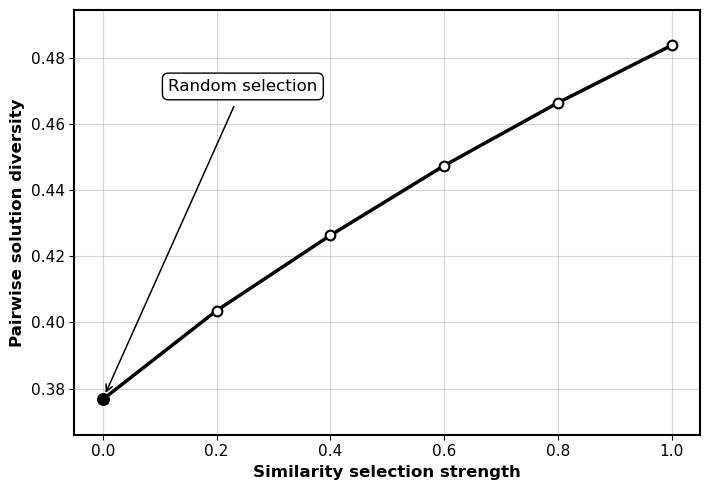

In [10]:
# =========================
# Pairwise diversity across similarity selection strength (average across K)
# =========================
fig, ax = plt.subplots(figsize=(7.2, 5.0))

# -------------------------
# Axis formatting
# -------------------------
for spine in ax.spines.values():
    spine.set_linewidth(1.5)
    spine.set_color("black")

ax.grid(alpha=0.5)
ax.tick_params(axis="both", labelsize=11)

# -------------------------
# Data
# -------------------------
x = np.asarray(similarity_selection_strength_list)
y_diversity = safe_nanmean(data["pairwise_diversity"], axis=1)

# Identify random-selection benchmark point
zero_idx = 0
zero_x, zero_y = x[zero_idx], y_diversity[zero_idx]

# -------------------------
# Main curve
# -------------------------
ax.plot(
    x,
    y_diversity,
    marker="o",
    linewidth=2.5,
    markersize=7,
    color="k",
    markerfacecolor="white",
    markeredgecolor="black",
    markeredgewidth=1.5,
    zorder=2,
)

# Give endpoint observations some breathing room
ax.margins(x=0.05, y=0.10)

# Highlight random-selection benchmark
ax.scatter(
    zero_x,
    zero_y,
    s=70,
    color="black",
    zorder=3,
)

# -------------------------
# Annotation-box style
# -------------------------
textbox_style = dict(
    boxstyle="round,pad=0.35",
    facecolor="white",
    edgecolor="black",
    linewidth=1.0,
)

arrow_style = dict(
    arrowstyle="->",
    linewidth=1.1,
    color="black",
    shrinkA=5,
    shrinkB=5,
)

# -------------------------
# Random-selection annotation
# -------------------------
ax.annotate(
    "Random selection",
    xy=(zero_x, zero_y),
    xycoords="data",
    xytext=(0.15, 0.82),
    textcoords="axes fraction",
    ha="left",
    va="center",
    fontsize=12,
    bbox=textbox_style,
    arrowprops=arrow_style,
    annotation_clip=True,
    zorder=4,
)

# -------------------------
# Axes
# -------------------------
ax.set_xticks(x)

ax.set_xlabel(
    "Similarity selection strength",
    fontweight="bold",
    fontsize=12,
)

ax.set_ylabel(
    "Pairwise solution diversity",
    fontweight="bold",
    fontsize=12,
)

plt.tight_layout()

if save_figures:
    output_png = figure_folder / "Pairwise_diversity_across_similarity_selection_strength.png"

    plt.savefig(
        output_png,
        dpi=300,
        bbox_inches="tight",
        transparent=True,
    )

    print("Saved:", output_png)

plt.show()

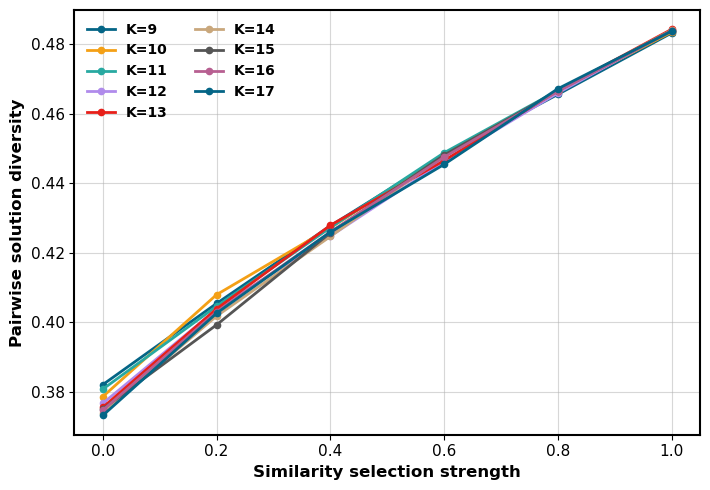

In [11]:
# Pairwise diversity across similarity selection strength (by K).
fig, ax = plt.subplots(figsize=(7.2, 5.0))
format_axis(ax)
for j, K in enumerate(K_list):
    ax.plot(x, data['pairwise_diversity'][:, j],
            marker='o', linewidth=2.0, markersize=4.5,
            label=f'K={K}', color=K_colors[j % len(K_colors)])
ax.set_xticks(x)
ax.set_xlabel('Similarity selection strength', fontweight='bold', fontsize=12)
ax.set_ylabel('Pairwise solution diversity', fontweight='bold', fontsize=12)
ax.legend(frameon=False, ncol=2, prop={'weight': 'bold', 'size': 10})
fig.tight_layout()
if save_figures:
    fig.savefig(figure_folder / 'Pairwise_diversity_by_K_across_similarity_selection_strength.png', dpi=300, bbox_inches='tight', transparent=True)
plt.show()

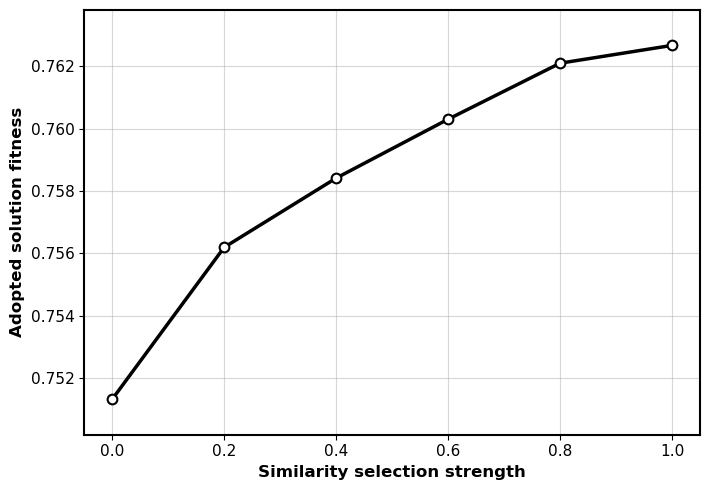

In [12]:
# Adopted solution fitness across similarity selection strength (average across K).
# At strength=0, recipients still see 10 fixed random sender entries, so adoption quality is defined
# whenever at least one sender solution is adopted.
fig, ax = plt.subplots(figsize=(7.2, 5.0))
format_axis(ax)

y_adopted = safe_nanmean(data['adopted_solution_fitness'], axis=1)

ax.plot(x, y_adopted, marker='o', linewidth=2.5, markersize=7, color='k',
        markerfacecolor='white', markeredgecolor='black', markeredgewidth=1.5)

ax.set_xticks(x)
ax.margins(x=0.05, y=0.10)
ax.set_xlabel('Similarity selection strength', fontweight='bold', fontsize=12)
ax.set_ylabel('Adopted solution fitness', fontweight='bold', fontsize=12)

fig.tight_layout()
if save_figures:
    fig.savefig(figure_folder / 'Adopted_solution_fitness_across_similarity_selection_strength.png',
                dpi=300, bbox_inches='tight', transparent=True)
plt.show()

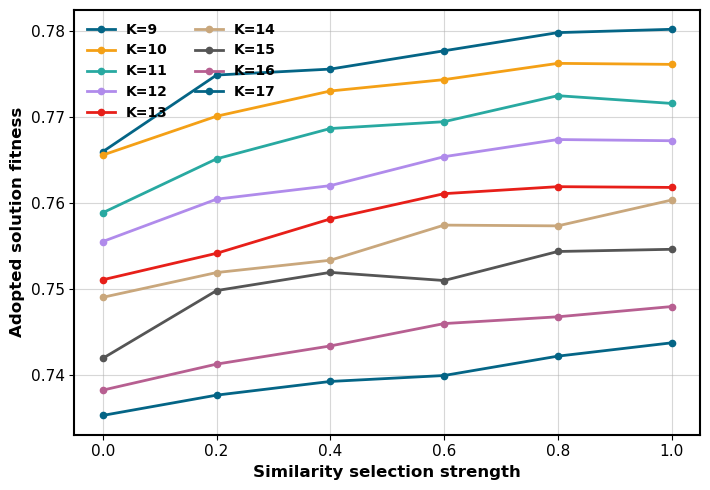

In [13]:
# Adopted solution fitness across similarity selection strength (by K).
fig, ax = plt.subplots(figsize=(7.2, 5.0))
format_axis(ax)
for j, K in enumerate(K_list):
    ax.plot(x, data['adopted_solution_fitness'][:, j],
            marker='o', linewidth=2.0, markersize=4.5,
            label=f'K={K}', color=K_colors[j % len(K_colors)])
ax.set_xticks(x)
ax.set_xlabel('Similarity selection strength', fontweight='bold', fontsize=12)
ax.set_ylabel('Adopted solution fitness', fontweight='bold', fontsize=12)
ax.legend(frameon=False, ncol=2, prop={'weight': 'bold', 'size': 10})
fig.tight_layout()
if save_figures:
    fig.savefig(figure_folder / 'Adopted_solution_fitness_by_K_across_similarity_selection_strength.png', dpi=300, bbox_inches='tight', transparent=True)
plt.show()

## 4. Additional outcomes

`breakthrough_fitness` records the best final recipient fitness, whereas `breakthrough_rank` records the corresponding best solution rank on the NK landscape. `unique_solution_count` counts distinct final recipient solutions, while normalized `pairwise_diversity` captures how far the solutions differ. Neither diversity measure changes the fixed recommendation count.

`generative_potential` is the simulation’s recipient-specific post-adoption continuation measure, averaged across runs with defined values. The script uses 30 additional search opportunities, 30 Monte Carlo continuations per sampled adoption, and up to five sampled adoptions per run. Undefined values are retained as NaN.

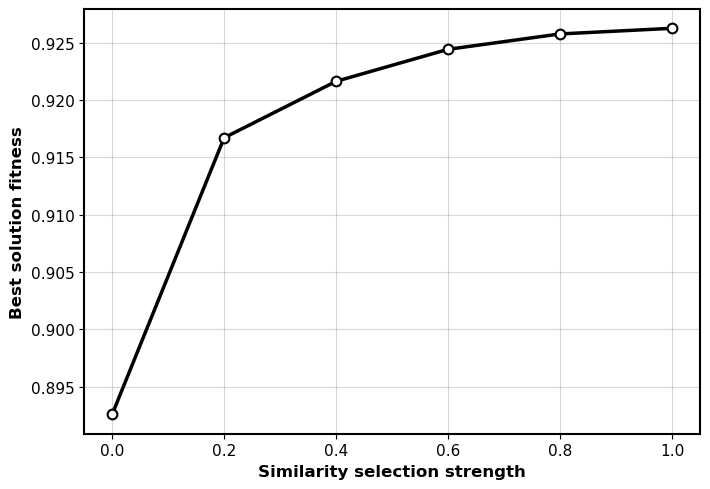

In [14]:
# Best solution fitness across similarity selection strength (average across K).
fig, ax = plt.subplots(figsize=(7.2, 5.0))
format_axis(ax)
y_fitness = safe_nanmean(data['breakthrough_fitness'], axis=1)
ax.plot(x, y_fitness, marker='o', linewidth=2.5, markersize=7, color='k',
        markerfacecolor='white', markeredgecolor='black', markeredgewidth=1.5)
ax.set_xticks(x)
ax.set_xlabel('Similarity selection strength', fontweight='bold', fontsize=12)
ax.set_ylabel('Best solution fitness', fontweight='bold', fontsize=12)
fig.tight_layout()
# if save_figures:
#     fig.savefig(figure_folder / 'Best_solution_fitness_across_similarity_selection_strength.png', dpi=300, bbox_inches='tight', transparent=True)
plt.show()

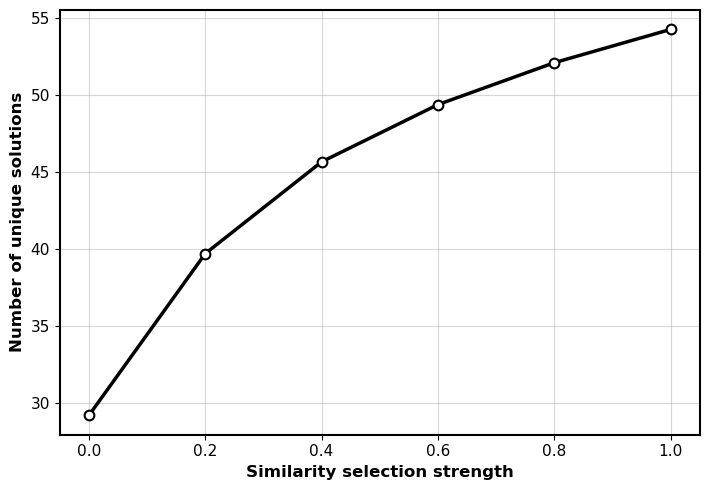

In [15]:
# Unique solution count across similarity selection strength (average across K).
fig, ax = plt.subplots(figsize=(7.2, 5.0))
format_axis(ax)
y_unique = safe_nanmean(data['unique_solution_count'], axis=1)
ax.plot(x, y_unique, marker='o', linewidth=2.5, markersize=7, color='k',
        markerfacecolor='white', markeredgecolor='black', markeredgewidth=1.5)
ax.set_xticks(x)
ax.set_xlabel('Similarity selection strength', fontweight='bold', fontsize=12)
ax.set_ylabel('Number of unique solutions', fontweight='bold', fontsize=12)
fig.tight_layout()
# if save_figures:
#     fig.savefig(figure_folder / 'Unique_solution_count_across_similarity_selection_strength.png', dpi=300, bbox_inches='tight', transparent=True)
plt.show()

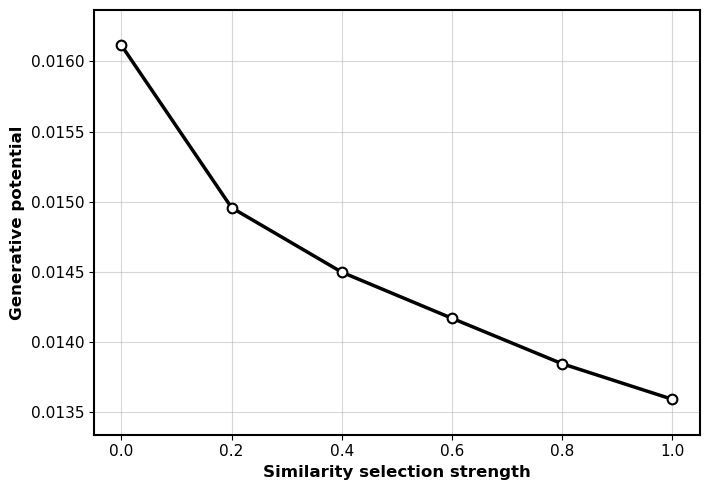

In [16]:
# Generative potential across similarity selection strength (average across K).
fig, ax = plt.subplots(figsize=(7.2, 5.0))
format_axis(ax)
y_generative = safe_nanmean(data['generative_potential'], axis=1)
ax.plot(x, y_generative, marker='o', linewidth=2.5, markersize=7, color='k',
        markerfacecolor='white', markeredgecolor='black', markeredgewidth=1.5)
ax.set_xticks(x)
ax.margins(x=0.05, y=0.10)
ax.set_xlabel('Similarity selection strength', fontweight='bold', fontsize=12)
ax.set_ylabel('Generative potential', fontweight='bold', fontsize=12)
fig.tight_layout()
if save_figures:
    fig.savefig(figure_folder / 'Generative_potential_across_similarity_selection_strength.png',
                dpi=300, bbox_inches='tight', transparent=True)
plt.show()

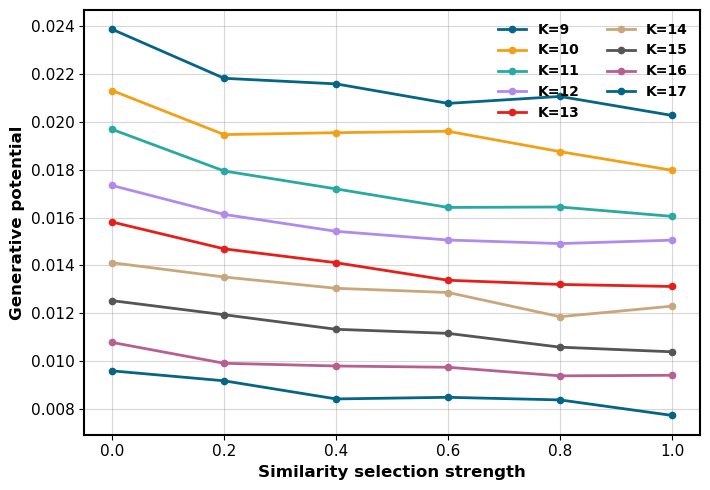

In [17]:
# Generative potential across similarity selection strength (by K).
fig, ax = plt.subplots(figsize=(7.2, 5.0))
format_axis(ax)
for j, K in enumerate(K_list):
    ax.plot(x, data['generative_potential'][:, j],
            marker='o', linewidth=2.0, markersize=4.5,
            label=f'K={K}', color=K_colors[j % len(K_colors)])
ax.set_xticks(x)
ax.set_xlabel('Similarity selection strength', fontweight='bold', fontsize=12)
ax.set_ylabel('Generative potential', fontweight='bold', fontsize=12)
ax.legend(frameon=False, ncol=2, prop={'weight': 'bold', 'size': 10})
fig.tight_layout()
if save_figures:
    fig.savefig(figure_folder / 'Generative_potential_by_K_across_similarity_selection_strength.png',
                dpi=300, bbox_inches='tight', transparent=True)
plt.show()

## 5. Cumulative adoption-quality trajectories

Set `trajectory_similarity_selection_strength` to any of the six simulated strengths. The horizontal axis gives visibility-event periods (`10, 20, ..., 300`). Each value is the **cumulative mean true fitness of adopted sender solutions through that event**, rather than the mean fitness of all recipient solutions or adoptions in only that period. Unlike a search-apart condition, the `0.0` random-selection condition can have a valid adoption-fitness trajectory.

In [18]:
trajectory_similarity_selection_strength = 1.0  # Any entry in similarity_selection_strength_list.
if trajectory_similarity_selection_strength not in similarity_selection_strength_list:
    raise ValueError('trajectory_similarity_selection_strength must appear in similarity_selection_strength_list.')
trajectory_index = similarity_selection_strength_list.index(trajectory_similarity_selection_strength)
trajectory_periods = np.arange(1, expected_events + 1) * visibility_interval
trajectory_by_K = data[trajectory_dv][trajectory_index]  # (K, visibility event)
print('Trajectory similarity selection strength:', trajectory_similarity_selection_strength)
print('Visibility events:', len(trajectory_periods), '| last search period:', trajectory_periods[-1])
print('Defined trajectory entries:', np.isfinite(trajectory_by_K).sum(), '/', trajectory_by_K.size)

Trajectory similarity selection strength: 1.0
Visibility events: 30 | last search period: 300
Defined trajectory entries: 270 / 270


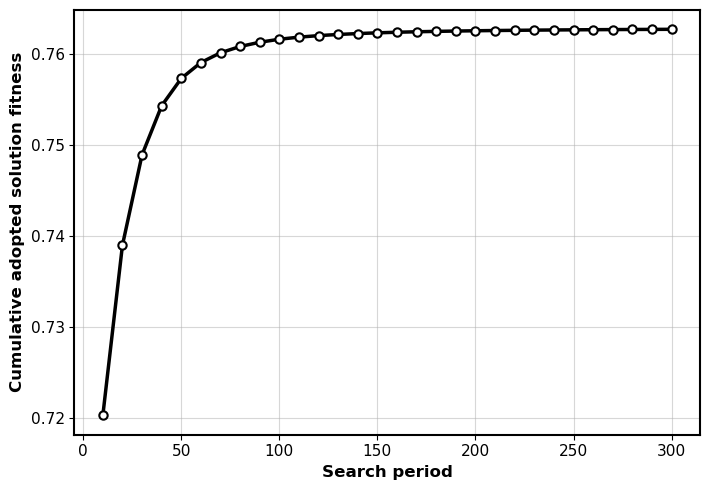

In [19]:
# Cumulative adopted solution fitness across search periods (average across K).
fig, ax = plt.subplots(figsize=(7.2, 5.0))
format_axis(ax)
trajectory_mean = safe_nanmean(trajectory_by_K, axis=0)
ax.plot(trajectory_periods, trajectory_mean, marker='o', linewidth=2.5,
        markersize=6, color='k', markerfacecolor='white', markeredgecolor='black', markeredgewidth=1.5)
ax.set_xlabel('Search period', fontweight='bold', fontsize=12)
ax.set_ylabel('Cumulative adopted solution fitness', fontweight='bold', fontsize=12)
fig.tight_layout()
# if save_figures:
#     fig.savefig(figure_folder / f'Adopted_solution_fitness_across_search_periods_similarity_selection_strength_{trajectory_similarity_selection_strength:g}.png', dpi=300, bbox_inches='tight', transparent=True)
plt.show()

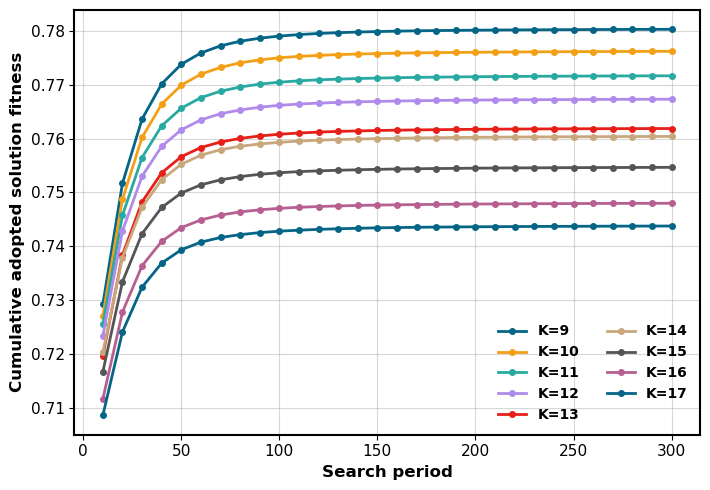

In [20]:
# Cumulative adopted solution fitness across search periods (by K).
fig, ax = plt.subplots(figsize=(7.2, 5.0))
format_axis(ax)
for j, K in enumerate(K_list):
    ax.plot(trajectory_periods, trajectory_by_K[j], marker='o',
            linewidth=2.0, markersize=4, color=K_colors[j % len(K_colors)],
            label=f'K={K}')
ax.set_xlabel('Search period', fontweight='bold', fontsize=12)
ax.set_ylabel('Cumulative adopted solution fitness', fontweight='bold', fontsize=12)
ax.legend(frameon=False, ncol=2, prop={'weight': 'bold', 'size': 10})
fig.tight_layout()
# if save_figures:
#     fig.savefig(figure_folder / f'Adopted_solution_fitness_by_K_across_search_periods_similarity_selection_strength_{trajectory_similarity_selection_strength:g}.png', dpi=300, bbox_inches='tight', transparent=True)
plt.show()

## 6. Similarity selection strength × landscape complexity

Heatmaps show **all six similarity selection-strength treatments** and each `K` separately. The `0.0` treatment is **fixed random selection**, not search-apart. The prioritization criterion is **similarity (smallest Hamming distance)**, rather than fitness rank; breakthrough ranks remain an outcome measure. Undefined adoption-quality and generative-potential cells are kept as missing values.

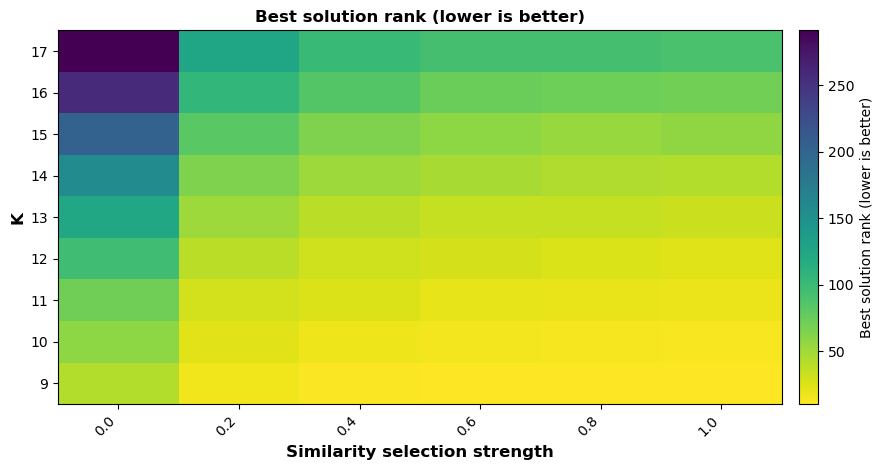

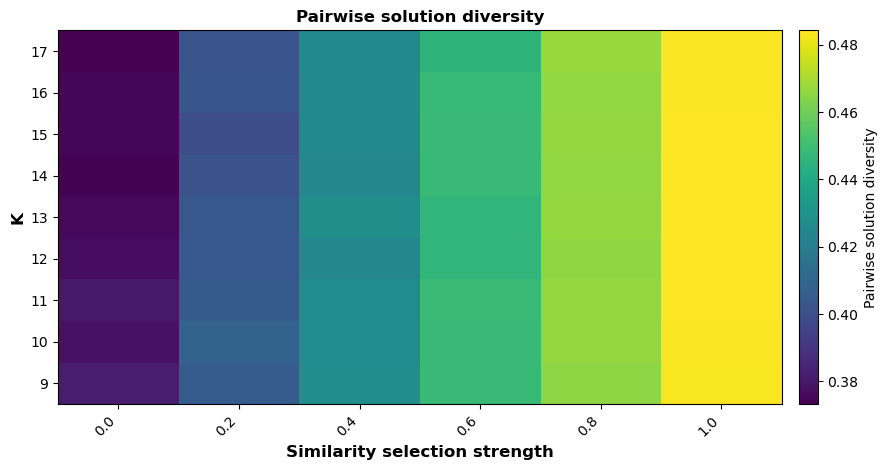

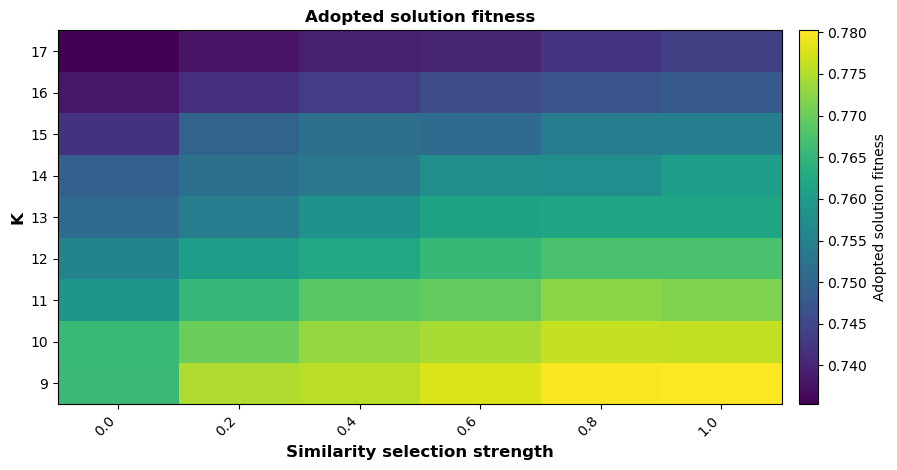

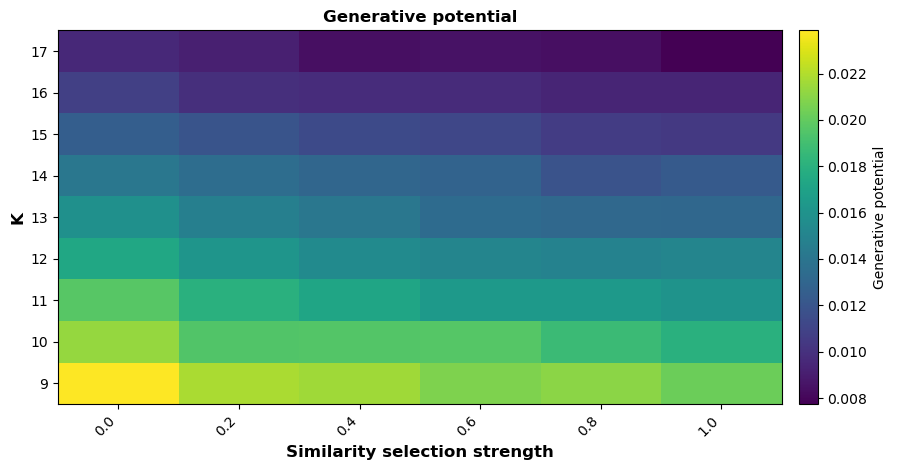

In [21]:
for dv, title, filename, cmap in [
    ('breakthrough_rank', 'Best solution rank (lower is better)', 'Best_solution_rank_heatmap_across_similarity_selection_strength_and_K.png', 'viridis_r'),
    ('pairwise_diversity', 'Pairwise solution diversity', 'Pairwise_diversity_heatmap_across_similarity_selection_strength_and_K.png', 'viridis'),
    ('adopted_solution_fitness', 'Adopted solution fitness', 'Adopted_solution_fitness_heatmap_across_similarity_selection_strength_and_K.png', 'viridis'),
    ('generative_potential', 'Generative potential', 'Generative_potential_heatmap_across_similarity_selection_strength_and_K.png', 'viridis'),
]:
    values = np.ma.masked_invalid(data[dv].T)  # (K, displayed similarity selection strength)
    fig, ax = plt.subplots(figsize=(9.5, 4.8))
    image = ax.imshow(values, aspect='auto', interpolation='nearest', cmap=cmap, origin='lower')
    ax.set_xticks(np.arange(len(similarity_selection_strength_list)))
    ax.set_xticklabels([f'{ratio:.1f}' for ratio in similarity_selection_strength_list], rotation=45, ha='right')
    ax.set_yticks(np.arange(len(K_list)))
    ax.set_yticklabels(K_list)
    ax.set_xlabel('Similarity selection strength', fontweight='bold', fontsize=12)
    ax.set_ylabel('K', fontweight='bold', fontsize=12)
    ax.set_title(title, fontweight='bold', fontsize=12)
    fig.colorbar(image, ax=ax, label=title, pad=0.02)
    fig.tight_layout()
    # if save_figures:
    #     fig.savefig(figure_folder / filename, dpi=300, bbox_inches='tight', transparent=True)
    plt.show()